# H&M 패션 데이터 탐색 보고서

H&M Personalized Fashion Recommendations의 상품 메타데이터, 구매 기록, 상품 이미지 피처를 함께 살펴본다. 원본 데이터는 로컬 data/h-and-m-personalized-fashion-recommendations/에 있어야 하며, 저장소 루트에서 JupyterLab을 실행한다.

고객 10,000명을 시드 42로 뽑고 **선택된 고객의 전체 관측 기간 거래**를 사용한다. 이미지 분석은 해당 거래에 나온 상품 중 이미지가 있는 1,500개를 같은 시드로 선택한다. 따라서 아래 결과는 이 표본에 관한 것이며 H&M 전체 고객으로 일반화하지 않는다. 거래 표의 `amount`는 원본 `transactions_train.csv`의 `price`를 이름만 바꾼 값이며 수량이 아니다. 원본에는 소수 가격값이 기록돼 있지만 실제 통화와 환산 기준은 확인되지 않는다. 따라서 표와 차트에서는 원본 가격값으로 부르고 특정 화폐 단위를 붙이지 않는다.

이 노트북은 이슈 4의 EDA·정적 차트까지 다룬다. RFM 세그먼트와 비즈니스 전략은 이슈 5에서 추가한다.

## 1. 데이터 경로와 파이프라인 실행

In [1]:
from pathlib import Path
import io

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

from src.pipeline import DataAnalyzer

data_dir = Path("data/h-and-m-personalized-fashion-recommendations")
required_paths = [data_dir / name for name in ("articles.csv", "customers.csv", "transactions_train.csv", "images")]
missing_paths = [str(path) for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError(f"원본 데이터가 없습니다: {missing_paths}. 저장소 루트에서 실행하세요.")
if not required_paths[-1].is_dir():
    raise NotADirectoryError(required_paths[-1])

figure_dir = Path("outputs/figures")
figure_dir.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=0.95)

analyzer = DataAnalyzer(data_dir, customer_count=10_000, image_count=1_500, seed=42).load_data()
products = analyzer.products.drop(columns=["image_array"])
transactions = analyzer.transactions
image_products = products.loc[products["image_mean"].notna()].copy()
print(f"선택 고객: {len(analyzer.customers):,}명")
print(f"유효 거래: {len(transactions):,}행 | 거래 상품: {len(products):,}개 | 이미지 피처 상품: {len(image_products):,}개")
print(f"관측 거래 기간: {transactions['order_date'].min().date()} ~ {transactions['order_date'].max().date()}")
print(f"RFM 기준일: {analyzer.reference_date.date()}")

선택 고객: 10,000명
유효 거래: 229,883행 | 거래 상품: 46,194개 | 이미지 피처 상품: 1,500개
관측 거래 기간: 2018-09-20 ~ 2020-09-22
RFM 기준일: 2020-09-23


## 2. 기본 탐색

In [2]:
# 이미지 배열은 크므로 표 출력에서 제외하고, 핵심 컬럼의 앞부분만 본다.
display(products[["product_id", "product_name", "category", "reference_price",
                  "product_name_word_count", "image_mean", "image_std"]].head())
display(transactions.head())

product_info = io.StringIO()
transaction_info = io.StringIO()
products.info(buf=product_info)
transactions.info(buf=transaction_info)
print("상품 표 info()\n" + product_info.getvalue())
print("거래 표 info()\n" + transaction_info.getvalue())

display(products[["reference_price", "product_name_word_count", "image_mean", "image_std"]].describe())
display(transactions[["amount", "sales_channel"]].describe())

,product_id,product_name,category,reference_price,product_name_word_count,image_mean,image_std
0,0108775015,Strap top,Garment Upper body,0.008458,2,NaN,NaN
1,0108775044,Strap top,Garment Upper body,0.008458,2,NaN,NaN
2,0108775051,Strap top (1),Garment Upper body,0.005068,3,NaN,NaN
3,0110065001,OP T-shirt (Idro),Underwear,0.024407,3,NaN,NaN
4,0110065002,OP T-shirt (Idro),Underwear,0.013542,3,NaN,NaN


,order_date,customer_id,product_id,amount,sales_channel
0,2018-09-20,00923f88cda50cbea4c5ceb2bd3467c620a9d74cb7da95...,0564786020,0.019814,1
1,2018-09-20,00923f88cda50cbea4c5ceb2bd3467c620a9d74cb7da95...,0655347002,0.015237,1
2,2018-09-20,00923f88cda50cbea4c5ceb2bd3467c620a9d74cb7da95...,0655347007,0.015237,1
3,2018-09-20,013cc00a6fe53e361d8b5da4153c5b8907c09bf951dd4e...,0590748001,0.064390,2
4,2018-09-20,01c8cb2f730cd7253bd3e290d98823894222b305139631...,0537688014,0.050831,1


상품 표 info()
<class 'pandas.DataFrame'>
RangeIndex: 46194 entries, 0 to 46193
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   product_id               46194 non-null  object 
 1   product_name             46194 non-null  str    
 2   category                 46194 non-null  str    
 3   description              46018 non-null  str    
 4   product_name_word_count  46194 non-null  int64  
 5   reference_price          46194 non-null  float64
 6   image_path               46065 non-null  object 
 7   image_mean               1500 non-null   float64
 8   image_std                1500 non-null   float64
 9   image_r_mean             1500 non-null   float64
 10  image_g_mean             1500 non-null   float64
 11  image_b_mean             1500 non-null   float64
 12  image_r_std              1500 non-null   float64
 13  image_g_std              1500 non-null   float64
 14  image_b_std          

,reference_price,product_name_word_count,image_mean,image_std
count,46194.000000,46194.000000,1500.000000,1500.000000
mean,0.030125,2.744794,173.078127,61.802737
std,0.022672,1.037604,42.318687,29.913580
min,0.000373,1.000000,42.599284,3.147697
25%,0.016282,2.000000,139.003031,34.654505
50%,0.025407,3.000000,178.503743,68.888861
75%,0.037695,3.000000,210.615540,88.242348
max,0.456102,8.000000,253.272380,108.713934


,amount,sales_channel
count,229883.000000,229883.000000
mean,0.027797,1.694371
std,0.018924,0.460674
min,0.000119,1.000000
25%,0.015966,1.000000
50%,0.025407,2.000000
75%,0.033881,2.000000
max,0.506780,2.000000


상품 표에는 **46,194개 상품**과 가격·카테고리·상품명·이미지 수치 피처가 있다. 거래 표에는 **229,883행**과 고객 ID·상품 ID·날짜·기록 가격이 있다. 이미지 평균·표준편차는 이미지가 선택된 **1,500개 상품**에만 채워져 있으므로, 이후 상관 분석도 이 1,500개에 한정한다.

상품의 관찰 가격 중앙값은 **0.025407**, 평균은 **0.030125**로 평균이 더 높다. 가격이 높은 상품 쪽으로 꼬리가 긴 분포인지 히스토그램에서 확인한다. 이 가격은 표본 거래에서 계산한 상품별 중앙값이며 정가가 아니다.

### 2.1 원본과 표본의 거래 분포 비교

두 집단 모두 구매 기록 한 행을 한 건으로 세어 가격 구간과 상품 카테고리의 비율을 비교한다. 원본 거래는 필요한 열만 청크로 읽는다. 가격값은 통화와 환산 기준을 알 수 없다.

In [3]:
# 가격과 카테고리를 모두 "구매 기록 1행" 기준으로 비교한다.
# 원본은 3,100만 행 이상이므로 필요한 열만 청크로 읽고 빈도만 누적한다.
from collections import Counter

category_by_article = pd.read_csv(
    data_dir / "articles.csv", usecols=["article_id", "product_group_name"],
    dtype={"article_id": "string"},
).set_index("article_id")["product_group_name"]

price_edges = [0, 0.01, 0.02, 0.04, 0.08, float("inf")]
price_labels = ["0–<0.01", "0.01–<0.02", "0.02–<0.04", "0.04–<0.08", "0.08 이상"]
source_price_counts = Counter()
source_category_counts = Counter()
source_rows = 0
for chunk in pd.read_csv(
    data_dir / "transactions_train.csv", usecols=["article_id", "price"],
    dtype={"article_id": "string"}, chunksize=500_000,
):
    if chunk["price"].isna().any() or chunk["price"].le(0).any():
        raise ValueError("원본 거래에 비어 있거나 0 이하인 가격이 있습니다.")
    chunk_categories = chunk["article_id"].map(category_by_article)
    if chunk_categories.isna().any():
        raise ValueError("원본 거래에 상품 표와 연결되지 않는 상품 ID가 있습니다.")
    chunk_price_groups = pd.cut(chunk["price"], bins=price_edges, labels=price_labels, right=False)
    source_price_counts.update(chunk_price_groups.value_counts().to_dict())
    source_category_counts.update(chunk_categories.value_counts().to_dict())
    source_rows += len(chunk)

sample_price_groups = pd.cut(
    transactions["amount"], bins=price_edges, labels=price_labels, right=False,
)
sample_price_counts = sample_price_groups.value_counts().to_dict()
sample_categories = transactions["product_id"].map(category_by_article)
if sample_categories.isna().any():
    raise ValueError("표본 거래에 상품 표와 연결되지 않는 상품 ID가 있습니다.")
sample_category_counts = sample_categories.value_counts().to_dict()

price_comparison = pd.DataFrame({
    "원본 거래 수": [source_price_counts[label] for label in price_labels],
    "표본 거래 수": [sample_price_counts.get(label, 0) for label in price_labels],
}, index=pd.Index(price_labels, name="원본 가격값 구간"))
price_comparison["원본 비율(%)"] = price_comparison["원본 거래 수"] / source_rows * 100
price_comparison["표본 비율(%)"] = price_comparison["표본 거래 수"] / len(transactions) * 100
price_comparison["비율 차이(%p)"] = price_comparison["표본 비율(%)"] - price_comparison["원본 비율(%)"]

all_categories = sorted(set(source_category_counts) | set(sample_category_counts))
category_comparison = pd.DataFrame({
    "원본 거래 수": [source_category_counts[category] for category in all_categories],
    "표본 거래 수": [sample_category_counts.get(category, 0) for category in all_categories],
}, index=pd.Index(all_categories, name="상품 카테고리"))
category_comparison["원본 비율(%)"] = category_comparison["원본 거래 수"] / source_rows * 100
category_comparison["표본 비율(%)"] = category_comparison["표본 거래 수"] / len(transactions) * 100
category_comparison["비율 차이(%p)"] = category_comparison["표본 비율(%)"] - category_comparison["원본 비율(%)"]
category_comparison = category_comparison.sort_values("원본 거래 수", ascending=False)

print(f"원본 거래 {source_rows:,}행 · 표본 유효 거래 {len(transactions):,}행")
display(price_comparison.round(2))
display(category_comparison.round(2))


원본 거래 31,788,324행 · 표본 유효 거래 229,883행


,원본 거래 수,표본 거래 수,원본 비율(%),표본 비율(%),비율 차이(%p)
원본 가격값 구간,,,,,
0–<0.01,3155753,22670,9.93,9.86,-0.07
0.01–<0.02,9231187,66477,29.04,28.92,-0.12
0.02–<0.04,13241412,96315,41.65,41.90,0.24
0.04–<0.08,5498231,39789,17.30,17.31,0.01
0.08 이상,661741,4632,2.08,2.01,-0.07


,원본 거래 수,표본 거래 수,원본 비율(%),표본 비율(%),비율 차이(%p)
상품 카테고리,,,,,
Garment Upper body,12552755,91420,39.49,39.77,0.28
Garment Lower body,7046054,51440,22.17,22.38,0.21
Garment Full body,3552470,25029,11.18,10.89,-0.29
Swimwear,2579222,18082,8.11,7.87,-0.25
Underwear,2565858,18577,8.07,8.08,0.01
Accessories,1599593,11577,5.03,5.04,0.00
Shoes,745521,5154,2.35,2.24,-0.10
Socks & Tights,685712,5203,2.16,2.26,0.11
Nightwear,348180,2590,1.10,1.13,0.03


원본 **31,788,324행**과 고객 표본의 유효 거래 **229,883행**을 같은 거래 행 기준으로 비교했다. 가장 큰 가격 구간인 `0.02–<0.04`는 원본 **41.65%**, 표본 **41.90%**다. 카테고리 `Garment Upper body`는 원본 **39.49%**, 표본 **39.77%**다. 표에 표시된 비율 차이는 가격 구간에서 최대 약 **0.24%p**, 카테고리에서 최대 약 **0.29%p**다. 이 두 분포가 비슷해 보여도 고객 10,000명 표본이 다른 고객 특성까지 전체를 대표한다는 뜻은 아니다.

## 3. 결측과 이상치 처리 효과

In [4]:
age_before = int(analyzer.raw_customers["age"].isna().sum())
age_after = int(analyzer.customers["age"].isna().sum())
missing_summary = pd.DataFrame({
    "stage": ["대치 전", "회원 상태별 중앙값 대치 후"],
    "customer_rows": [len(analyzer.raw_customers), len(analyzer.customers)],
    "age_missing": [age_before, age_after],
})
display(missing_summary)
print("age 대치 세부 내역:", analyzer.quality_report["age_imputation"])
print("상품 설명 결측:", int(products["description"].isna().sum()), "건 — 임의 문구로 대치하지 않음")

outlier_mask, iqr_bounds = analyzer.detect_outliers(transactions, "amount")
clipped_transactions, clip_report = analyzer.treat_outliers(transactions, "amount", method="clip")
outlier_summary = pd.DataFrame({
    "stage": ["원본 유효 거래", "IQR 경계값 절단"],
    "rows": [len(transactions), len(clipped_transactions)],
    "원본 가격값 최소": [transactions["amount"].min(), clipped_transactions["amount"].min()],
    "원본 가격값 중앙값": [transactions["amount"].median(), clipped_transactions["amount"].median()],
    "원본 가격값 최대": [transactions["amount"].max(), clipped_transactions["amount"].max()],
    "original_bounds_outliers": [
        int(outlier_mask.sum()),
        int(((clipped_transactions["amount"] < iqr_bounds["lower"]) |
             (clipped_transactions["amount"] > iqr_bounds["upper"])).sum()),
    ],
})
display(pd.DataFrame([iqr_bounds]).round(6))
display(outlier_summary.round(6))

,stage,customer_rows,age_missing
0,대치 전,10000,126
1,회원 상태별 중앙값 대치 후,10000,0


age 대치 세부 내역: {'target': 'age', 'group': 'club_member_status', 'strategy': 'median', 'before_missing': 126, 'group_filled': 126, 'global_filled': 0, 'after_missing': 0}
상품 설명 결측: 176 건 — 임의 문구로 대치하지 않음


,q1,q3,iqr,lower,upper,outlier_count
0,0.015966,0.033881,0.017915,-0.010907,0.060754,11132


,stage,rows,원본 가격값 최소,원본 가격값 중앙값,원본 가격값 최대,original_bounds_outliers
0,원본 유효 거래,229883,0.000119,0.025407,0.506780,11132
1,IQR 경계값 절단,229883,0.000119,0.025407,0.060754,0


고객 나이 결측은 **126/10,000건에서 0건**으로 줄었다. 이 표본에서는 회원 상태별 중앙값으로 126건을 모두 채웠다. 상품 설명은 **176건**이 비어 있지만 없는 설명을 임의로 만들지 않았다.

거래 가격의 IQR 상한은 **0.060754**이고 범위 밖 거래는 **11,132/229,883건(4.84%)**이다. 비교용 복사본에서는 상한을 넘는 값을 경계에 맞췄으나 행 수는 그대로다. **RFM 금액은 절단 전 유효 거래**로 계산되므로 이 처리의 영향을 받지 않는다.

## 4. 이미지·텍스트 피처와 통계 관계

In [5]:
feature_columns = ["reference_price", "image_mean", "image_std", "product_name_word_count"]
feature_stats = image_products[feature_columns].describe().T
feature_correlation = image_products[feature_columns].corr(method="pearson")
display(feature_stats[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(4))
display(feature_correlation.round(4))
print("가격–이미지 평균 상관계수:",
      round(feature_correlation.loc["reference_price", "image_mean"], 4))
print("가격–상품명 단어 수 상관계수:",
      round(feature_correlation.loc["reference_price", "product_name_word_count"], 4))

,count,mean,std,min,25%,50%,75%,max
reference_price,1500.0,0.0302,0.0223,0.0008,0.0164,0.0254,0.0381,0.2698
image_mean,1500.0,173.0781,42.3187,42.5993,139.0030,178.5037,210.6155,253.2724
image_std,1500.0,61.8027,29.9136,3.1477,34.6545,68.8889,88.2423,108.7139
product_name_word_count,1500.0,2.7700,1.0388,1.0000,2.0000,3.0000,3.0000,6.0000


,reference_price,image_mean,image_std,product_name_word_count
reference_price,1.0000,-0.1547,0.0826,-0.0727
image_mean,-0.1547,1.0000,-0.8510,0.0902
image_std,0.0826,-0.8510,1.0000,-0.0285
product_name_word_count,-0.0727,0.0902,-0.0285,1.0000


가격–이미지 평균 상관계수: -0.1547
가격–상품명 단어 수 상관계수: -0.0727


이미지가 있는 1,500개 상품에서 관찰 가격과 이미지 평균의 Pearson 상관계수는 **-0.1547**, 관찰 가격과 상품명 단어 수는 **-0.0727**이다. 모두 약한 선형 관계다. 이미지 평균과 이미지 표준편차 사이의 상관계수는 **-0.8510**이지만, 촬영 배경과 상품 색의 영향이 섞였을 수 있다. 상관관계만으로 가격의 원인을 설명할 수 없다.

## 5. 필수 시각화

### 5.1 상품 관찰 가격 히스토그램

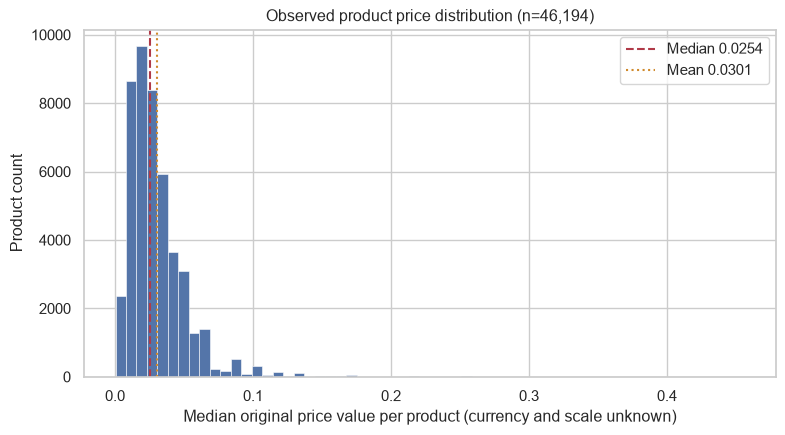

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(products["reference_price"].dropna(), bins=60, color="#5475a9", edgecolor="white", linewidth=0.4)
ax.axvline(products["reference_price"].median(), color="#b03a48", linestyle="--",
           label=f"Median {products['reference_price'].median():.4f}")
ax.axvline(products["reference_price"].mean(), color="#d08a2c", linestyle=":",
           label=f"Mean {products['reference_price'].mean():.4f}")
ax.set(title=f"Observed product price distribution (n={len(products):,})",
       xlabel="Median original price value per product (currency and scale unknown)", ylabel="Product count")
ax.legend()
fig.tight_layout()
fig.savefig(figure_dir / "01-product-price-histogram.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

평균 **0.030125**가 중앙값 **0.025407**보다 높고 최대값은 **0.456102**여서 오른쪽 꼬리가 길다. 상품별 표본 거래 가격의 중앙값을 그린 것으로, 카탈로그 정가의 분포는 아니다.

### 5.2 거래 가격 IQR 처리 전후 박스플롯

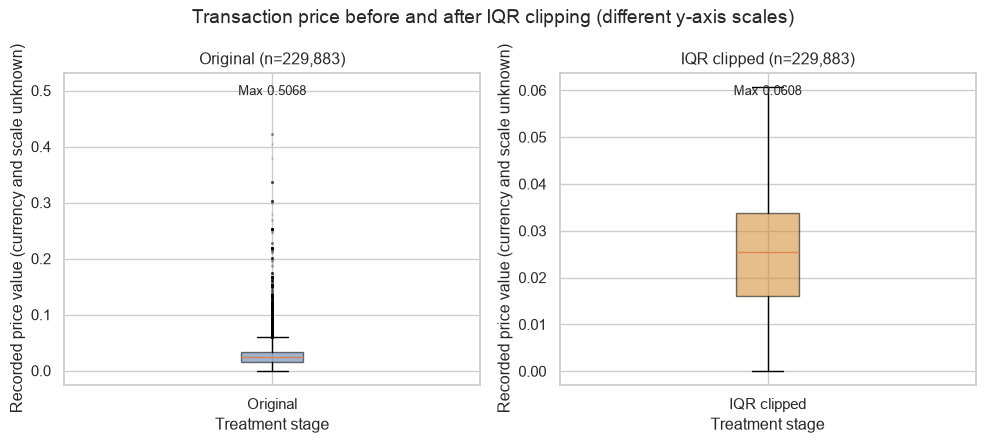

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, values, label, color in [
    (axes[0], transactions["amount"], "Original", "#5475a9"),
    (axes[1], clipped_transactions["amount"], "IQR clipped", "#d08a2c"),
]:
    ax.boxplot(values.to_numpy(), showfliers=True, patch_artist=True,
               boxprops={"facecolor": color, "alpha": 0.55},
               flierprops={"marker": "o", "markersize": 1.1, "alpha": 0.12})
    ax.set(title=f"{label} (n={len(values):,})",
           xlabel="Treatment stage", ylabel="Recorded price value (currency and scale unknown)")
    ax.set_xticks([1], [label])
    ax.text(0.5, 0.96, f"Max {values.max():.4f}", transform=ax.transAxes,
            va="top", ha="center", fontsize=9)
fig.suptitle("Transaction price before and after IQR clipping (different y-axis scales)")
fig.tight_layout()
fig.savefig(figure_dir / "02-amount-iqr-boxplot.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

IQR 경계 밖의 **11,132건**을 표시한 뒤 비교용 표에서 상한 **0.060754**로 절단했다. 원본 최대 **0.506780**과 절단 후 최대 **0.060754**의 차이를 보기 위해 패널마다 y축 범위를 따로 사용했다. 행은 제거하지 않았고 RFM용 거래도 바꾸지 않았다.

### 5.3 거래 상품 카테고리별 빈도 막대그래프

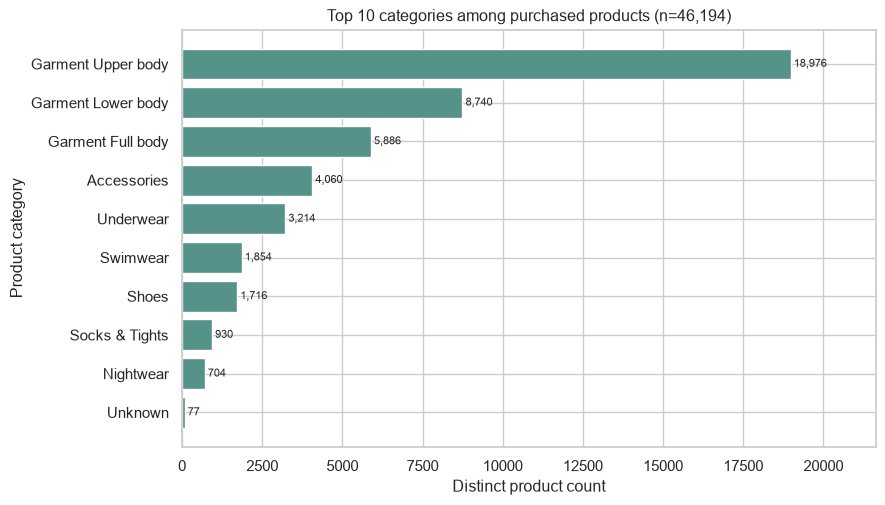

In [8]:
category_counts = products["category"].value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(category_counts.index, category_counts.values, color="#54928a")
ax.set(title=f"Top 10 categories among purchased products (n={len(products):,})",
       xlabel="Distinct product count", ylabel="Product category")
for row, count in enumerate(category_counts.values):
    ax.text(count + 100, row, f"{count:,}", va="center", fontsize=8)
ax.set_xlim(0, category_counts.max() * 1.14)
fig.tight_layout()
fig.savefig(figure_dir / "03-category-counts.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

가장 많은 카테고리는 **Garment Upper body 18,976개**로 거래 상품 46,194개의 약 **41.1%**다. 이는 선택 고객이 구매한 고유 상품의 구성이고 전체 H&M 상품 목록이나 판매량 비중은 아니다.

### 5.4 피처 상관행렬 히트맵

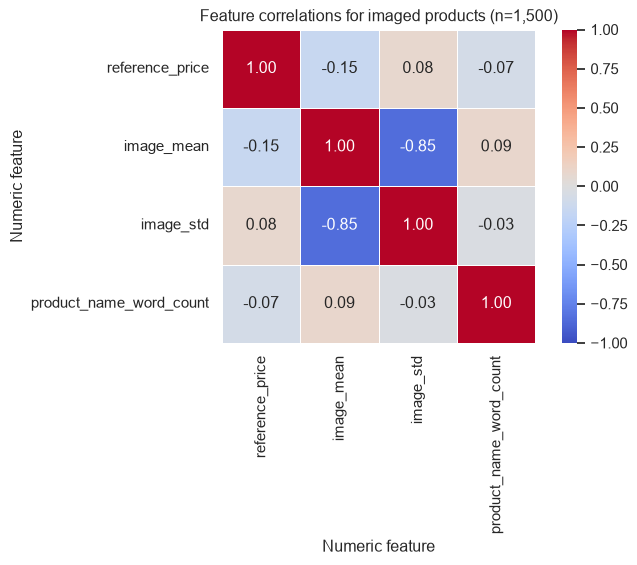

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 5.8))
sns.heatmap(feature_correlation, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, ax=ax)
ax.set(title=f"Feature correlations for imaged products (n={len(image_products):,})",
       xlabel="Numeric feature", ylabel="Numeric feature")
fig.tight_layout()
fig.savefig(figure_dir / "04-feature-correlation-heatmap.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

관찰 가격–이미지 평균은 **-0.1547**, 관찰 가격–상품명 단어 수는 **-0.0727**이다. 이미지 평균–표준편차는 **-0.8510**으로 더 크지만 이미지의 배경·색 구성이 함께 작용할 수 있어 상품 특성의 인과 효과로 해석하지 않는다.

### 5.5 관찰 가격과 이미지 평균 산점도

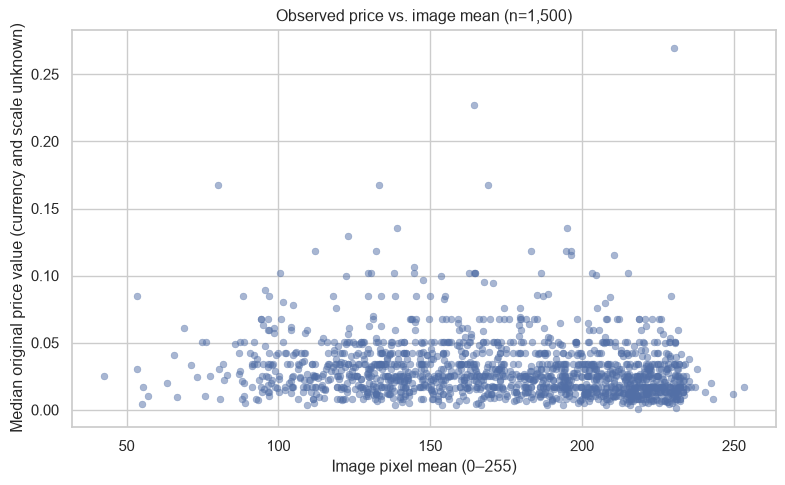

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=image_products, x="image_mean", y="reference_price",
                color="#526fa6", alpha=0.5, s=24, edgecolor=None, ax=ax)
ax.set(title=f"Observed price vs. image mean (n={len(image_products):,})",
       xlabel="Image pixel mean (0–255)", ylabel="Median original price value (currency and scale unknown)")
fig.tight_layout()
fig.savefig(figure_dir / "05-price-image-mean-scatter.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

점들의 선형 관계는 약하며 Pearson 상관계수는 **-0.1547**이다. 이미지가 밝다고 가격이 낮아진다는 뜻은 아니다. 상품 종류·색상·촬영 배경을 통제하지 않은 탐색 결과다.

### 5.6 월별 기록된 구매 가격 합계 라인차트

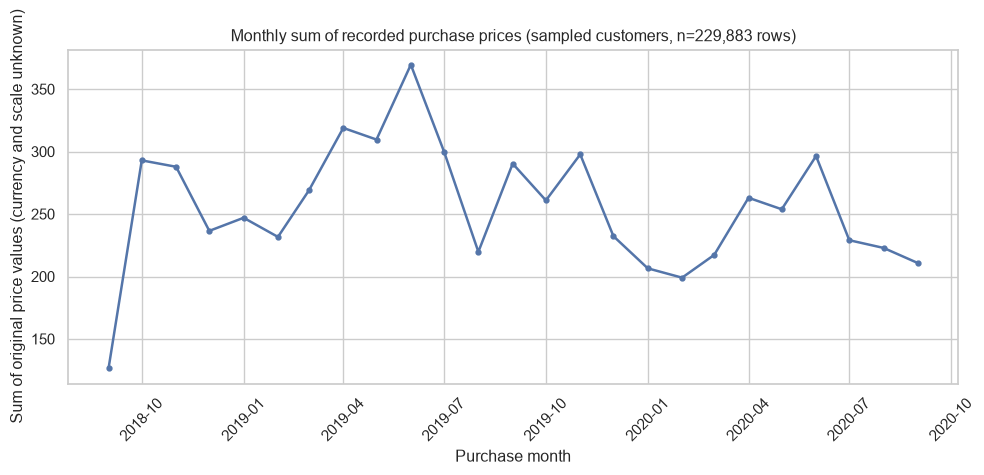

In [11]:
monthly_amount = transactions.groupby(transactions["order_date"].dt.to_period("M"))["amount"].sum()
monthly_dates = monthly_amount.index.to_timestamp()
fig, ax = plt.subplots(figsize=(10, 4.7))
ax.plot(monthly_dates, monthly_amount.to_numpy(), marker="o", markersize=3.5,
        color="#5475a9", linewidth=1.8)
ax.set(title=f"Monthly sum of recorded purchase prices (sampled customers, n={len(transactions):,} rows)",
       xlabel="Purchase month", ylabel="Sum of original price values (currency and scale unknown)")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(figure_dir / "06-monthly-recorded-price-sum.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

표본 거래의 월별 기록 가격 합계는 **2019-06에 약 369.600**으로 가장 높다. 관측 기간은 **2018-09-20~2020-09-22**여서 첫 달과 마지막 달은 완전한 한 달이 아니다. 가격의 통화·단위와 취소·반품 상태를 알 수 없으므로 확정 매출로 부르지 않는다.